# pMoE and MGE: comparing head settings, trained end-to-end

**What it does.** Trains the two most promising models from `MoE_comparisons`, **pMoE** (experts that look at a few image patches) and **MGE** (one expert per backbone depth), each with several settings (the two grids below), so you can see which setting works best. Every run builds its **own new backbone** and trains it together with its head:

* **Phase A** - backbone + head trained **end-to-end from scratch** for at most `EPOCHS` epochs, **with augmentation** (`AUG`) from the first epoch to fight the overfitting seen in `MoE_comparisons`.
* **Phase B** (optional, off by default) - `FINETUNE_EPOCHS` more epochs of the whole model on clean images at the small `FINETUNE_LR`.

**How to run**
1. Run the cells from top to bottom. The cells you may want to edit are **Settings** and the two grids.
2. To look at results again **without training**, set `USE_SAVED = True` (first code cell) and run everything: weights and logs are loaded from disk (or from GitHub on a new pod).
3. Add, remove or change entries of the two grids as you like. To retrain just one setting, leave only that entry in its grid and run again: the comparison at the end also reads the logs of earlier runs with the same `RUN_TAG` from `pMoE_MGE_finetune/history_logs/`.
4. Logs and weights (backbone + head) go to this notebook's own folder, `pMoE_MGE_finetune/`.

Only the **validation** split is used to choose settings; the test split is used once at the end, for the two winners.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [2]:
USE_SAVED = False   # True: load the saved backbone, head weights and logs instead of training (analyse old runs)

import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')
#os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')   # take GPU memory as needed, not all of it at start (kernels can then share a GPU)

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        # fetch + hard reset instead of `pull`: always lands on the newest origin commit, even if the VM copy diverged
        subprocess.run(['git', '-C', ROOT, 'fetch', 'origin'], check=True)
        subprocess.run(['git', '-C', ROOT, 'reset', '--hard', '@{u}'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 69
NB_DIR = 'pMoE_MGE_finetune'   # this notebook's output folder (relative to the project root)
MODELS_DIR = f'{NB_DIR}/models'          # backbones and head weights
HISTORY_DIR = f'{NB_DIR}/history_logs'   # one CSV log per training run
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: local machine
Project root: /home/20240644


In [3]:
# the kernel survives between runs: drop every cached utils module so the code git just pulled is what gets imported
for _m in [m for m in sys.modules if m == 'utils' or m.startswith('utils.')]:
    del sys.modules[_m]
from utils.funcs import *
from utils import config, github_sync, plotting, resnet
from utils.github_sync import save_csv, load_csv, push_files
from utils.MoE import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import f1_score
tf.keras.mixed_precision.set_global_policy('mixed_float16')

I0000 00:00:1795206760.911586 3634500 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795206760.949059 3634500 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795206762.115277 3634500 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Where the results go
Logs go to `pMoE_MGE_finetune/history_logs/`, backbones and model weights to `pMoE_MGE_finetune/models/` (this notebook's own output folder). A RunPod pod or Colab VM loses its disk when it ends, so the next cell offers two ways to keep them:
* **Push to GitHub:** paste a GitHub token into the box (hidden, kept in memory only). Everything is then committed to the `checkpoints` branch as soon as it is written, and a new pod downloads the saved backbone from there instead of training it again. Leave the box empty to skip.
* **Copy to your PC:** run `.\pull_results.ps1 -Ip <ip> -Port <port>` before you terminate the pod (see the README).

Running locally you can ignore this cell: everything stays in the project folder.

In [4]:
# Is the disk temporary? Colab VM, or a RunPod pod (pod_bootstrap.sh clones the repo into /workspace).
ON_POD = ROOT.startswith('/workspace/') or bool(os.environ.get('RUNPOD_POD_ID'))
REMOTE = IN_COLAB or ON_POD
if REMOTE:
    config.ensure_github()      # asks once for a GitHub token (hidden box, kept in memory only); empty = no upload
USE_GITHUB = REMOTE and config.github_ready()

if USE_GITHUB:
    _, repo, branch = config.github_settings()
    print(f'Results -> GitHub {repo}@{branch}: every log, backbone and weight file is committed when it is written')
elif ON_POD:
    print('Results stay on the pod. Copy them to your PC before terminating it:  .\\pull_results.ps1 -Ip <ip> -Port <port>')
else:
    print(f'Results -> local folders ({HISTORY_DIR}/, {MODELS_DIR}/)')

Results -> local folders (pMoE_MGE_finetune/history_logs/, pMoE_MGE_finetune/models/)


In [5]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

In [6]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

## Data
Images are resized to 64x64. The training set is **not** rebalanced here (`CLASS_BALANCE = None`). Setting `CLASS_BALANCE = 'oversample'` and `CLASS_BALANCE_TARGET = 'median'` repeats images of the small classes up to the median class size. Validation and test are never resampled.

In [7]:
SIZE, BATCH, AUTOTUNE = 64, 128, tf.data.AUTOTUNE
CLASS_BALANCE = None         # train set only: None | "oversample" | "undersample"  (see funcs.balance_frame)
CLASS_BALANCE_TARGET = None  # images per class: None (max / min) | "min" | "median" | "max" | int

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (SIZE, SIZE))
    return tf.cast(tf.round(img), tf.uint8), y        # uint8: 4x smaller in the RAM cache below

def make_ds(split, shuffle):
    df = dfs[split]
    if split == "train" and CLASS_BALANCE:      # never resample val / test
        df = balance_frame(df, CLASS_BALANCE, CLASS_BALANCE_TARGET, seed=SEED)
        n = df["class_id"].value_counts()
        print(f"train balanced ({CLASS_BALANCE}): {len(df)} images, {n.min()}-{n.max()} per class")
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()   # decode + resize ONCE; later epochs read from RAM
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)                  # after cache(), so the order still changes every epoch
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

I0000 00:00:1795206762.637514 3634500 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 45777 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:41:00.0, compute capability: 8.6


200 classes
image_000002.JPEG True
(128, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Settings
Everything you might want to change is in the next cell and in the two grids further down.

* **Backbone** - `blocks` is the number of residual blocks per stage, `drop` the dropout inside the backbone.
* **Phase A** (end-to-end) - at most `EPOCHS` epochs, `WARMUP_EPOCHS` linear warmup to `LR`, then cosine decay to 0; AdamW with `WEIGHT_DECAY`. With `USE_AUG = True` it trains on augmented images (`AUG`) from the first epoch.
* **Phase B** (optional) - `FINETUNE_EPOCHS` more epochs of the whole model on **clean** training images, starting at `FINETUNE_LR` with cosine decay to 0 (`FINETUNE_EPOCHS = 0` switches it off). Augmentation only in a short fine-tuning phase did not work: every run dropped to about the same, lower val F1, because 10 slow epochs are far too few to relearn the features from augmented images.
* Both phases stop early after `PATIENCE` epochs without a better validation loss and keep the best epoch's weights.

In [8]:
# ======== Settings ========

# --- backbone architecture (every run builds its own new copy and trains it together with its head)
BACKBONE = dict(
    blocks=(2, 2, 3, 4),   # residual blocks per stage; fewer blocks = faster epochs
    drop=0.3,             # dropout inside the backbone (after stage 3)
)

# --- phase A: backbone + head end-to-end from scratch
EPOCHS = 60               # max epochs = length of the cosine schedule
LR = 0.01                 # PEAK learning rate (linear warmup, then cosine decay to 0)
WARMUP_EPOCHS = 5
WEIGHT_DECAY = 0.05       # AdamW, applied as lr * wd per step; not on bias / BN
PATIENCE = 5              # early stopping (both phases): epochs without a better val loss
USE_AUG = True            # phase A trains on augmented images (AUG below)

# --- phase B: a few more epochs of the whole model on CLEAN images at a small learning rate
FINETUNE_EPOCHS = 0       # 0 = off
FINETUNE_LR = 1e-4        # start learning rate, cosine decay to 0 (no warmup: the model is already trained)

# --- heads
FEATURE_DROP = 0.3        # pMoE: SpatialDropout2D on s3
N_EXPERTS = 8             # pMoE: number of experts
L_PATCHES = 16            # pMoE: patches each expert keeps (at most H x W of s3)
DIVERSITY_WEIGHT = 0.01   # MGE: weight of the diversity penalty

RUN_TAG = f'e2e_{EPOCHS}ep_lr{LR:g}' + ('_aug' if USE_AUG else '') + (f'_ft{FINETUNE_EPOCHS}' if FINETUNE_EPOCHS else '')   # end of every log / weights name

AUG = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom((-0.2, 0.1)),        # mostly zoom in = random crop
    layers.RandomRotation(0.05),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2, value_range=(0, 255)),   # inputs are still 0..255 here
])

# the augmentation runs in the input pipeline, so the models themselves stay the same
train_aug = train.map(lambda x, y: (tf.cast(AUG(x, training=True), tf.float32), y), num_parallel_calls=AUTOTUNE)

STEPS = int(train.cardinality())   # batches per epoch
LR_SCHEDULE = tf.keras.optimizers.schedules.CosineDecay(0.0, decay_steps=(EPOCHS - WARMUP_EPOCHS) * STEPS,
                                                        warmup_target=LR, warmup_steps=WARMUP_EPOCHS * STEPS)


def run(model, name, epochs=EPOCHS, gate=False, initial_epoch=0, save=True, data=train):
    """Train `model` and return its History; with USE_SAVED, load its saved weights and log instead.
    Log: <HISTORY_DIR>/<name>.csv, weights (best epoch): <MODELS_DIR>/<name>.weights.h5, both pushed to GitHub if USE_GITHUB.
    initial_epoch > 0 continues an earlier run: its epochs are appended to the same log. data: the training set."""
    log_path, weights_path = f'{HISTORY_DIR}/{name}.csv', f'{MODELS_DIR}/{name}.weights.h5'
    if USE_SAVED:
        for p in (log_path, weights_path):
            if not resnet.fetch_if_missing(p, USE_GITHUB):
                raise FileNotFoundError(f'{p} is missing: train this run first (USE_SAVED = False)')
        model.load_weights(weights_path)
        history = tf.keras.callbacks.History()
        history.history = pd.read_csv(log_path).to_dict('list')
    else:
        callbacks = ([GateMonitor(val)] if gate else []) + [       # before CSVLogger, so their values land in the log
            MacroF1(val),
            tf.keras.callbacks.CSVLogger(log_path, append=initial_epoch > 0),
            tf.keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)]
        history = model.fit(data, validation_data=val, initial_epoch=initial_epoch, epochs=initial_epoch + epochs,
                            callbacks=callbacks)
        files = {log_path: log_path}
        if save:
            model.save_weights(weights_path)
            files[weights_path] = weights_path
        if USE_GITHUB:
            push_files(files, f'run: {name}')
    plot_history(history)
    return history

### Run bookkeeping

In [9]:
import gc
BEST_F1 = {}   # model type -> best val macro-F1 so far (only that run keeps its Keras model)
RUNS = {}   # run name -> dict(model, settings, log (DataFrame), net (Keras model; only kept for the best run of each type, else None))


def get_run(name, build, model, settings):
    """Phase A: train build() (backbone + head) end-to-end from scratch, on augmented images if USE_AUG. Phase B
    (FINETUNE_EPOCHS > 0): a few more epochs of the whole model on clean images at FINETUNE_LR. Both phases go into
    one log and one weights file.
    With USE_SAVED the saved weights and log are loaded; a run without saved weights is read from its log only."""
    print(f'===== {name}')
    tf.keras.backend.clear_session()
    net = build()
    log_path = f'{HISTORY_DIR}/{name}.csv'
    if USE_SAVED and not resnet.fetch_if_missing(f'{MODELS_DIR}/{name}.weights.h5', USE_GITHUB):
        print(f'{name}: no saved weights, only its log is used')
        if not resnet.fetch_if_missing(log_path, USE_GITHUB):
            raise FileNotFoundError(f'{log_path} is missing too: train this run first (USE_SAVED = False)')
        net = None
    else:
        history = run(net, name, data=train_aug if USE_AUG else train)
        if FINETUNE_EPOCHS and not USE_SAVED:
            compile_head(net, tf.keras.optimizers.schedules.CosineDecay(FINETUNE_LR, FINETUNE_EPOCHS * STEPS),
                         WEIGHT_DECAY)
            run(net, name, FINETUNE_EPOCHS, initial_epoch=len(history.epoch), data=train)
    log = pd.read_csv(log_path)
    # GPU memory: keep only the best model of each type (the winners cells need just those), free the rest
    f1 = log['val_f1'].max()
    if net is not None and f1 > BEST_F1.get(model, -1):
        BEST_F1[model] = f1
        for r in RUNS.values():
            if r['model'] == model:
                r['net'] = None
    else:
        net = None
    gc.collect()
    tf.keras.backend.clear_session()
    RUNS[name] = dict(model=model, settings=settings, log=log, net=net)
    return log, net

## The backbone
A ResNet written for 64x64 images (no early downsampling), written as the function `backbone` below, so you can change it right there (layers, widths; the number of blocks per stage is `BACKBONE['blocks']`). It must return the three feature maps `[s1, s2, s3]` (shallow to deep): `s1` 32x32x64, `s2` 16x16x128, `s3` 8x8x256. pMoE reads `s3`, MGE reads all three.

`fresh_backbone` builds a **new, trainable** copy for every run, so all runs start from the same architecture but never share weights.

In [10]:
# The backbone: edit it freely. It must return [s1, s2, s3] (shallow -> deep); the settings come from BACKBONE above.
def backbone(inp):
    """Conv layers only (no augmentation) -> [s1, s2, s3], shallow -> deep."""
    drop, (n1, n2, n3, n4) = BACKBONE['drop'], BACKBONE['blocks']
    x = layers.Rescaling(1 / 255)(inp)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)     # stem: 64 x 64 x 32
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # stage 1: 64 x 64 x 32 (shared low-level feature extractor)
    for _ in range(n1):
        x = res_block(x, 32, downsample=False)

    # stage 2: 32 x 32 x 64
    x = res_block(x, 64)
    for _ in range(n2 - 1):
        x = res_block(x, 64, downsample=False)
    s1 = x                                        # MGE expert 0 (32 x 32 x 64)

    # stage 3: 16 x 16 x 128
    x = res_block(x, 128)
    for _ in range(n3 - 1):
        x = res_block(x, 128, downsample=False)
    s2 = x                                        # MGE expert 1 (16 x 16 x 128)
    x = layers.SpatialDropout2D(drop)(x)

    # stage 4: 8 x 8 x 256
    x = res_block(x, 256)
    for _ in range(n4 - 1):
        x = res_block(x, 256, downsample=False)
    s3 = x                                        # MGE expert 2, pMoE feature map (8 x 8 x 256)

    return [s1, s2, s3]


def fresh_backbone(inp, augmentation=None):
    """A NEW, trainable backbone for every run, trained together with its head: image -> [s1, s2, s3]."""
    x = augmentation(inp) if augmentation is not None else inp
    return backbone(x)

## Head settings to compare
Each entry is one run; its key is the short name in the logs. The first entry of each grid uses the settings above (`N_EXPERTS`, `L_PATCHES`, `DIVERSITY_WEIGHT`). Add, remove or change entries freely; to retrain just one setting, keep only that entry.

In [11]:
# pMoE: number of experts and patches kept per expert.   MGE: weight of the diversity penalty.
PMOE_GRID = {f'e{n}_l{l}': dict(n_experts=n, l=l) for n, l in [(N_EXPERTS, L_PATCHES), (16, 8)]}
MGE_GRID = {f'div{w}': dict(diversity_weight=w) for w in [DIVERSITY_WEIGHT, 0.3]}
print(list(PMOE_GRID), list(MGE_GRID))

['e8_l16', 'e16_l8'] ['div0.01', 'div0.3']


## pMoE sweep

===== pmoe_e8_l16_e2e_40ep_lr0.01_aug
Epoch 1/40


E0000 00:00:1795206765.333993 3634500 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
I0000 00:00:1795206773.673205 3634935 service.cc:153] XLA service 0x7ef60c073e20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795206773.673230 3634935 service.cc:161]   StreamExecutor [0]: NVIDIA RTX A6000, Compute Capability 8.6 (Driver: 12.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1795206773.996130 3634935 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795206775.549743 3634935 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1795206775.915737 3634935 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28904__.319
I0000 00:00:1795206781.177289 3634935 dot_search_space.cc:240] All configs were filtered out because none of them su

  2/329 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.0039 - loss: 9.1259   

I0000 00:00:1795206790.428792 3634935 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.0167 - loss: 5.4541

I0000 00:00:1795206809.459497 3634932 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_28904__.319
I0000 00:00:1795206811.201207 3634932 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795206811.484278 3634932 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795206811.682267 3636665 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_88', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1795206811.730732 3634932 dot_search_space.cc:240] All configs were filtered out because non

329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.0167 - loss: 5.4539

I0000 00:00:1795206821.663030 3634932 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_8', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1795206826.950956 3634937 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795206827.120523 3637938 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_56', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1795206827.199986 3637944 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_56', 12 bytes spill stores, 12 bytes spill loads



  val macro-F1 0.0047
329/329 ━━━━━━━━━━━━━━━━━━━━ 67s 129ms/step - accuracy: 0.0167 - loss: 5.4539 - val_accuracy: 0.0203 - val_loss: 5.2025 - val_f1: 0.0047
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.0363 - loss: 4.9504  val macro-F1 0.0084
329/329 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.0363 - loss: 4.9504 - val_accuracy: 0.0289 - val_loss: 5.0527 - val_f1: 0.0084
Epoch 3/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.0458 - loss: 4.8393  val macro-F1 0.0041
329/329 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.0458 - loss: 4.8393 - val_accuracy: 0.0207 - val_loss: 5.9152 - val_f1: 0.0041
Epoch 4/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.0567 - loss: 4.7641  val macro-F1 0.0103
329/329 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.0567 - loss: 4.7642 - val_accuracy: 0.0336 - val_loss: 5.0080 - val_f1: 0.0103
Epoch 5/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0615 - loss: 4.7160  val macro-F1 0.0259
3

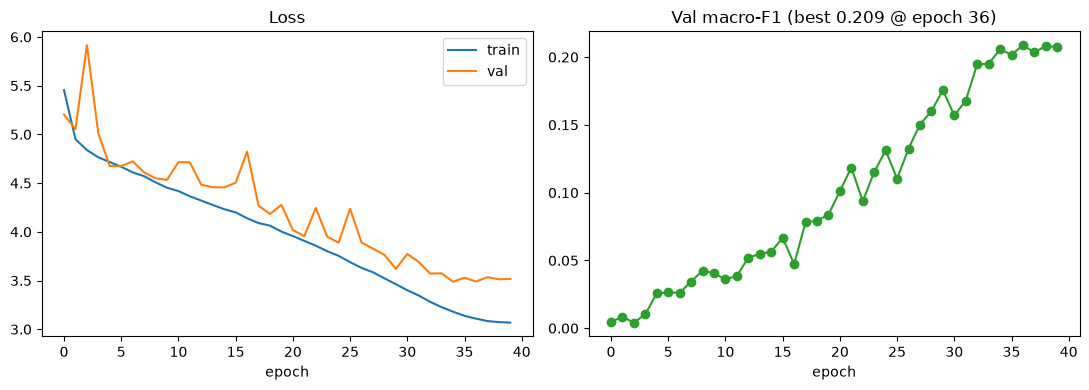

===== pmoe_e16_l8_e2e_40ep_lr0.01_aug
Epoch 1/40


I0000 00:00:1795207622.187197 3634936 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_166961__.407


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0144 - loss: 5.7325

I0000 00:00:1795207651.568795 3634936 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_166961__.407
I0000 00:00:1795207652.101635 3634936 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795207652.375366 3634936 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795207652.570299 3659035 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_224', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1795207652.776040 3634936 dot_search_space.cc:240] All configs were filtered out because n

329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.0144 - loss: 5.7323

I0000 00:00:1795207666.410018 3634933 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


  val macro-F1 0.0009
329/329 ━━━━━━━━━━━━━━━━━━━━ 65s 128ms/step - accuracy: 0.0144 - loss: 5.7323 - val_accuracy: 0.0103 - val_loss: 5.1965 - val_f1: 8.8718e-04
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0282 - loss: 5.0285  val macro-F1 0.0045
329/329 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.0282 - loss: 5.0285 - val_accuracy: 0.0244 - val_loss: 5.3592 - val_f1: 0.0045
Epoch 3/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0373 - loss: 4.9278  val macro-F1 0.0097
329/329 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.0373 - loss: 4.9277 - val_accuracy: 0.0386 - val_loss: 5.0748 - val_f1: 0.0097
Epoch 4/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.0443 - loss: 4.8746  val macro-F1 0.0061
329/329 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.0443 - loss: 4.8746 - val_accuracy: 0.0251 - val_loss: 5.1830 - val_f1: 0.0061
Epoch 5/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0482 - loss: 4.8458  val macro-F1 0.01

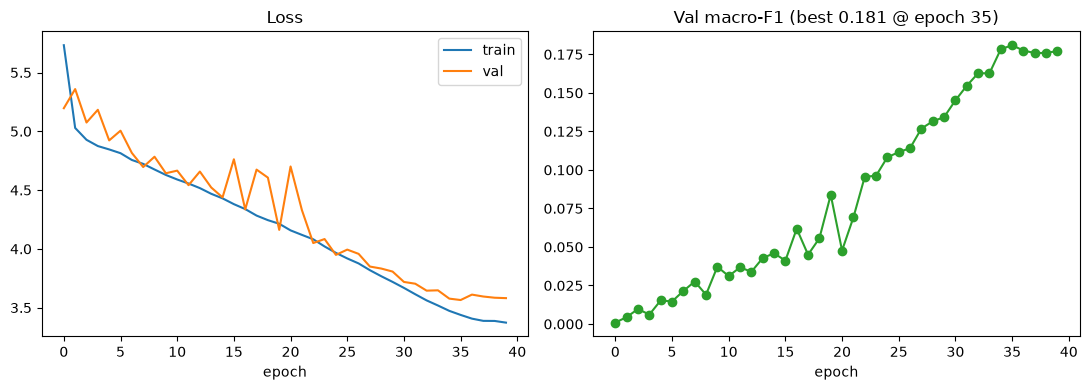

In [12]:
for key, cfg in PMOE_GRID.items():
    get_run(f'pmoe_{key}_{RUN_TAG}',
            lambda: build_pmoe(SIZE, len(classes), fresh_backbone, drop=FEATURE_DROP, lr=LR_SCHEDULE,
                               weight_decay=WEIGHT_DECAY, **cfg),
            'pmoe', key)

## MGE sweep

===== mge_div0.01_e2e_40ep_lr0.01_aug
Epoch 1/40


I0000 00:00:1795208475.589628 3634932 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_295092__.301
I0000 00:00:1795208477.093420 3634932 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795208477.298741 3680212 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_6', 32 bytes spill stores, 32 bytes spill loads



328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - ensemble_accuracy: 0.0366 - ensemble_loss: 4.9887 - expert_0_accuracy: 0.0297 - expert_0_loss: 5.0618 - expert_1_accuracy: 0.0345 - expert_1_loss: 5.0348 - expert_2_accuracy: 0.0301 - expert_2_loss: 5.0587 - loss: 20.1524

I0000 00:00:1795208503.828988 3634933 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_295092__.301


329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - ensemble_accuracy: 0.0366 - ensemble_loss: 4.9887 - expert_0_accuracy: 0.0297 - expert_0_loss: 5.0620 - expert_1_accuracy: 0.0345 - expert_1_loss: 5.0346 - expert_2_accuracy: 0.0301 - expert_2_loss: 5.0587 - loss: 20.1524

I0000 00:00:1795208514.310347 3634935 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


  val macro-F1 0.0106
329/329 ━━━━━━━━━━━━━━━━━━━━ 53s 110ms/step - ensemble_accuracy: 0.0366 - ensemble_loss: 4.9887 - expert_0_accuracy: 0.0297 - expert_0_loss: 5.0620 - expert_1_accuracy: 0.0345 - expert_1_loss: 5.0346 - expert_2_accuracy: 0.0301 - expert_2_loss: 5.0587 - loss: 20.1524 - val_ensemble_accuracy: 0.0380 - val_ensemble_loss: 4.9683 - val_expert_0_accuracy: 0.0377 - val_expert_0_loss: 4.9200 - val_expert_1_accuracy: 0.0420 - val_expert_1_loss: 4.9334 - val_expert_2_accuracy: 0.0327 - val_expert_2_loss: 5.5453 - val_loss: 20.3393 - val_f1: 0.0106
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - ensemble_accuracy: 0.0634 - ensemble_loss: 4.7099 - expert_0_accuracy: 0.0555 - expert_0_loss: 4.7732 - expert_1_accuracy: 0.0599 - expert_1_loss: 4.7407 - expert_2_accuracy: 0.0553 - expert_2_loss: 4.7696 - loss: 19.0021  val macro-F1 0.0056
329/329 ━━━━━━━━━━━━━━━━━━━━ 22s 65ms/step - ensemble_accuracy: 0.0634 - ensemble_loss: 4.7087 - expert_0_accuracy: 0.0555 - expert_0_l

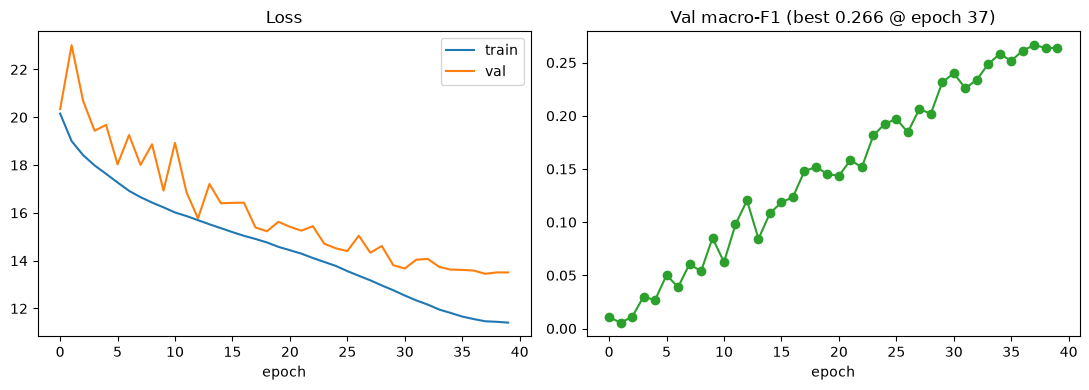

===== mge_div0.3_e2e_40ep_lr0.01_aug
Epoch 1/40


I0000 00:00:1795209379.663909 3634937 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_585919__.301


328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - ensemble_accuracy: 0.0364 - ensemble_loss: 4.9917 - expert_0_accuracy: 0.0299 - expert_0_loss: 5.0754 - expert_1_accuracy: 0.0322 - expert_1_loss: 5.0484 - expert_2_accuracy: 0.0302 - expert_2_loss: 5.0605 - loss: 20.4243

I0000 00:00:1795209405.447074 3634936 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_585919__.301


329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - ensemble_accuracy: 0.0364 - ensemble_loss: 4.9904 - expert_0_accuracy: 0.0300 - expert_0_loss: 5.0737 - expert_1_accuracy: 0.0322 - expert_1_loss: 5.0473 - expert_2_accuracy: 0.0302 - expert_2_loss: 5.0593 - loss: 20.4236  val macro-F1 0.0072
329/329 ━━━━━━━━━━━━━━━━━━━━ 47s 101ms/step - ensemble_accuracy: 0.0364 - ensemble_loss: 4.9904 - expert_0_accuracy: 0.0300 - expert_0_loss: 5.0737 - expert_1_accuracy: 0.0322 - expert_1_loss: 5.0473 - expert_2_accuracy: 0.0302 - expert_2_loss: 5.0593 - loss: 20.4236 - val_ensemble_accuracy: 0.0317 - val_ensemble_loss: 5.3052 - val_expert_0_accuracy: 0.0294 - val_expert_0_loss: 5.0091 - val_expert_1_accuracy: 0.0320 - val_expert_1_loss: 5.4096 - val_expert_2_accuracy: 0.0214 - val_expert_2_loss: 6.6520 - val_loss: 22.4819 - val_f1: 0.0072
Epoch 2/40
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - ensemble_accuracy: 0.0640 - ensemble_loss: 4.7047 - expert_0_accuracy: 0.0570 - expert_0_loss: 4.7803 - expert_1_

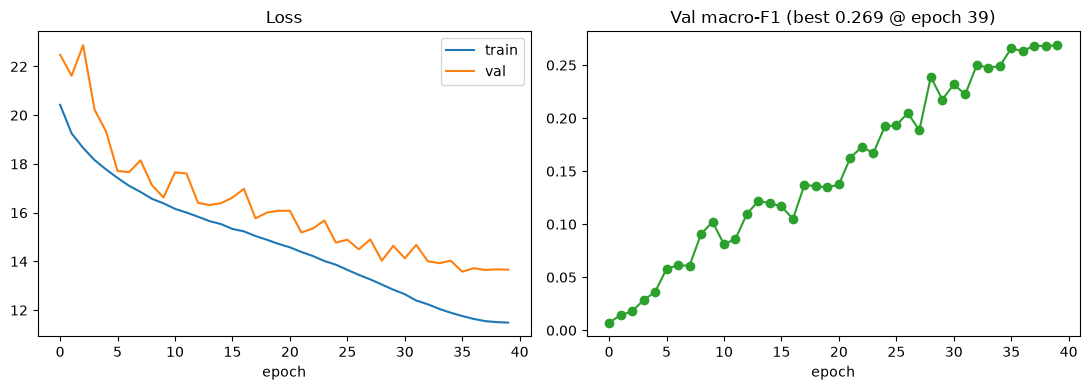

In [13]:
for key, cfg in MGE_GRID.items():
    get_run(f'mge_{key}_{RUN_TAG}',
            lambda: build_mge(SIZE, len(classes), fresh_backbone, lr=LR_SCHEDULE, weight_decay=WEIGHT_DECAY, **cfg),
            'mge', key)

## Comparison
All choices are made on the **validation** set. For MGE the figures use its `ensemble` output.
Logs of earlier runs with the same `RUN_TAG` are added, so retraining a single setting still shows everything.

In [14]:
# add the runs with THIS RUN_TAG whose logs already exist (earlier sessions, other grids)
for model in ('pmoe', 'mge'):
    for f in sorted(os.listdir(HISTORY_DIR)):
        if f.startswith(f'{model}_') and f.endswith(f'_{RUN_TAG}.csv'):
            name = f[:-4]
            if name not in RUNS:
                RUNS[name] = dict(model=model, settings=name[len(model) + 1:-len(RUN_TAG) - 1],
                                  log=pd.read_csv(os.path.join(HISTORY_DIR, f)), net=None)


def runs_of(model):
    return {n: r for n, r in RUNS.items() if r['model'] == model}


def label(r):
    return f"{r['model']} {r['settings']}"


def val_acc(log):
    return log['val_ensemble_accuracy'] if 'val_ensemble_accuracy' in log else log['val_accuracy']


summary = pd.DataFrame([dict(run=n, model=r['model'], settings=r['settings'],
                             epochs_run=len(r['log']), best_val_f1=r['log']['val_f1'].max(),
                             at_epoch=int(r['log']['val_f1'].values.argmax()), best_val_acc=val_acc(r['log']).max())
                        for n, r in RUNS.items()]).sort_values('best_val_f1', ascending=False)
best = {m: summary[summary['model'] == m]['run'].iloc[0] for m in ['pmoe', 'mge'] if (summary['model'] == m).any()}
print('best on val:', best)
summary.round(4)

best on val: {'pmoe': 'pmoe_e8_l16_e2e_40ep_lr0.01_aug', 'mge': 'mge_div0.3_e2e_40ep_lr0.01_aug'}


,run,model,settings,epochs_run,best_val_f1,at_epoch,best_val_acc
3,mge_div0.3_e2e_40ep_lr0.01_aug,mge,div0.3,40,0.2688,39,0.3428
2,mge_div0.01_e2e_40ep_lr0.01_aug,mge,div0.01,40,0.2664,37,0.3400
0,pmoe_e8_l16_e2e_40ep_lr0.01_aug,pmoe,e8_l16,40,0.2087,36,0.2800
1,pmoe_e16_l8_e2e_40ep_lr0.01_aug,pmoe,e16_l8,40,0.1809,35,0.2552


**Reading the table.** MGE beats pMoE by about 6 F1 points (0.27 vs 0.21). For MGE the diversity weight hardly matters (0.2688 vs 0.2664). For pMoE, fewer experts that each keep more patches (`e8_l16`) beat more experts with fewer patches (`e16_l8`). Every run used all 40 epochs and peaked in the last few, so early stopping never fired: the models are **under-trained, not overfitting**.

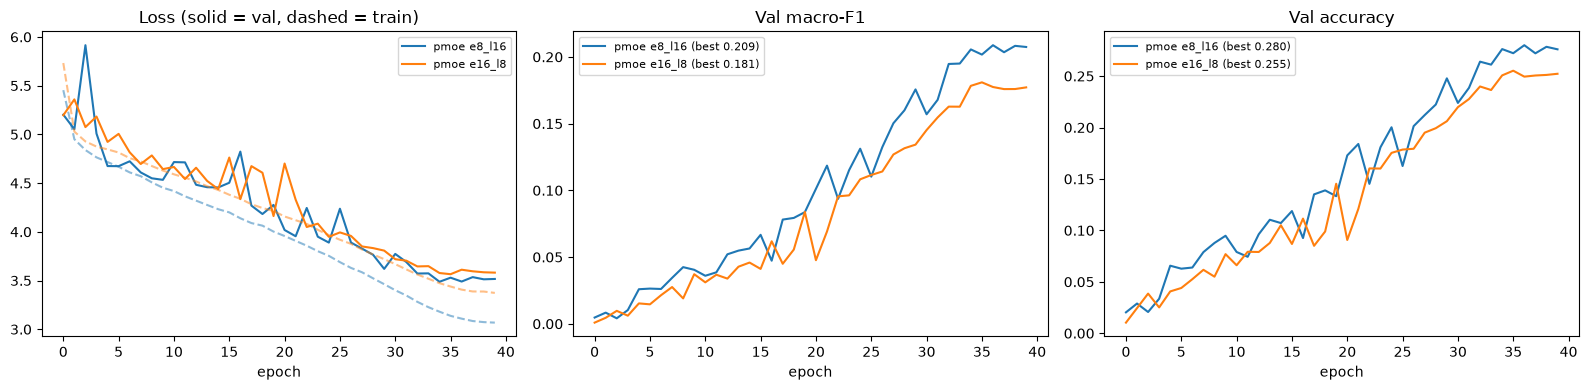

In [15]:
# pMoE: every head setting
plotting.plot_comparison({label(r): r['log'] for r in runs_of('pmoe').values()})

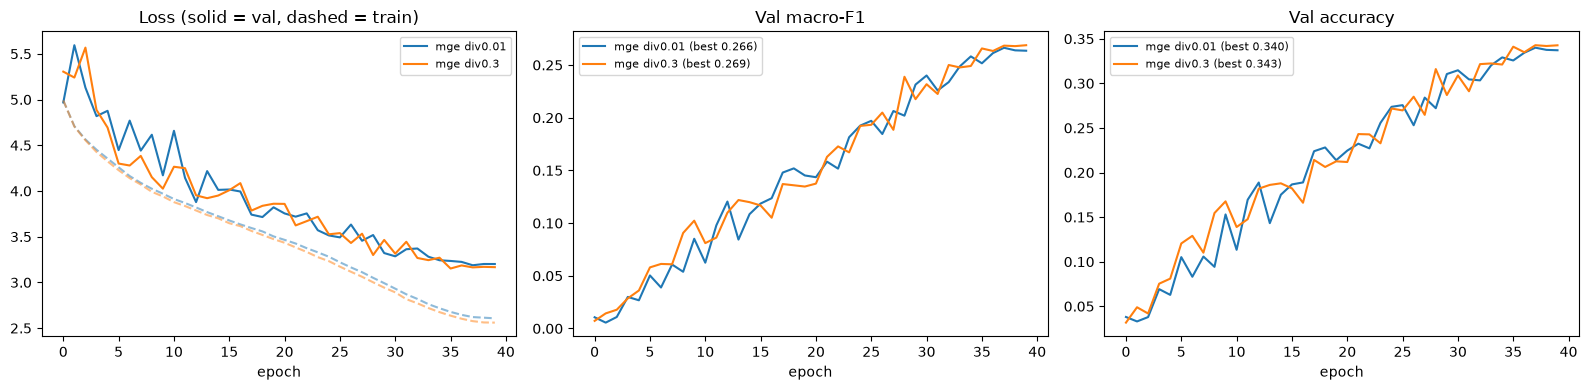

In [16]:
# MGE: every head setting
plotting.plot_comparison({label(r): r['log'] for r in runs_of('mge').values()})

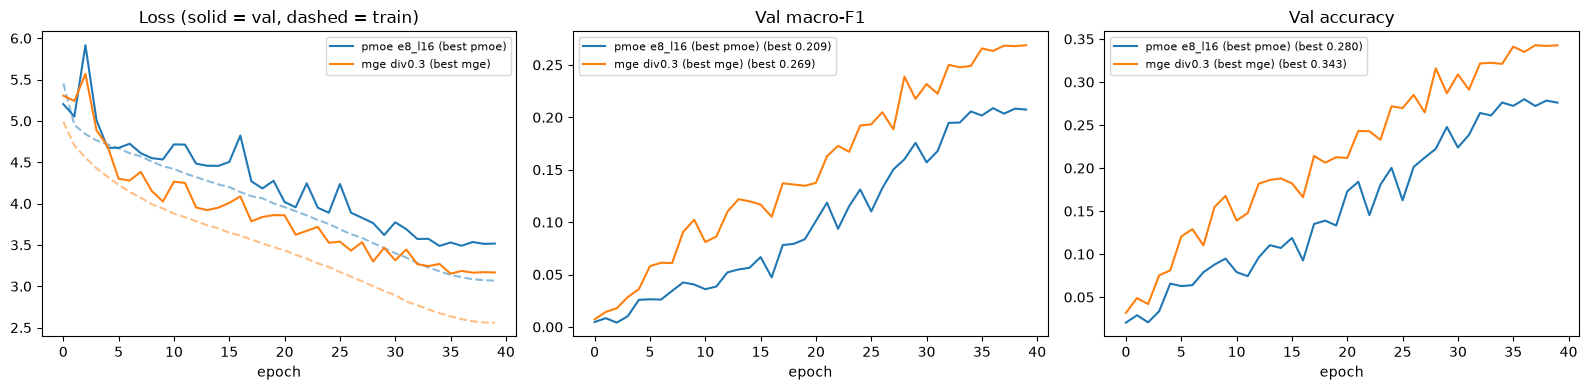

In [17]:
# head to head: the best pMoE vs the best MGE
plotting.plot_comparison({f'{label(RUNS[n])} (best {m})': RUNS[n]['log'] for m, n in best.items()})

## The two winners up close
pMoE: which patches each expert picks (needs the trained model, so not for a run read from its log).
MGE: how good each expert is on its own.

pmoe_e8_l16_e2e_40ep_lr0.01_aug: top_idx (64, 8, 16) = (images, experts, l patches);  patch grid (8, 8)


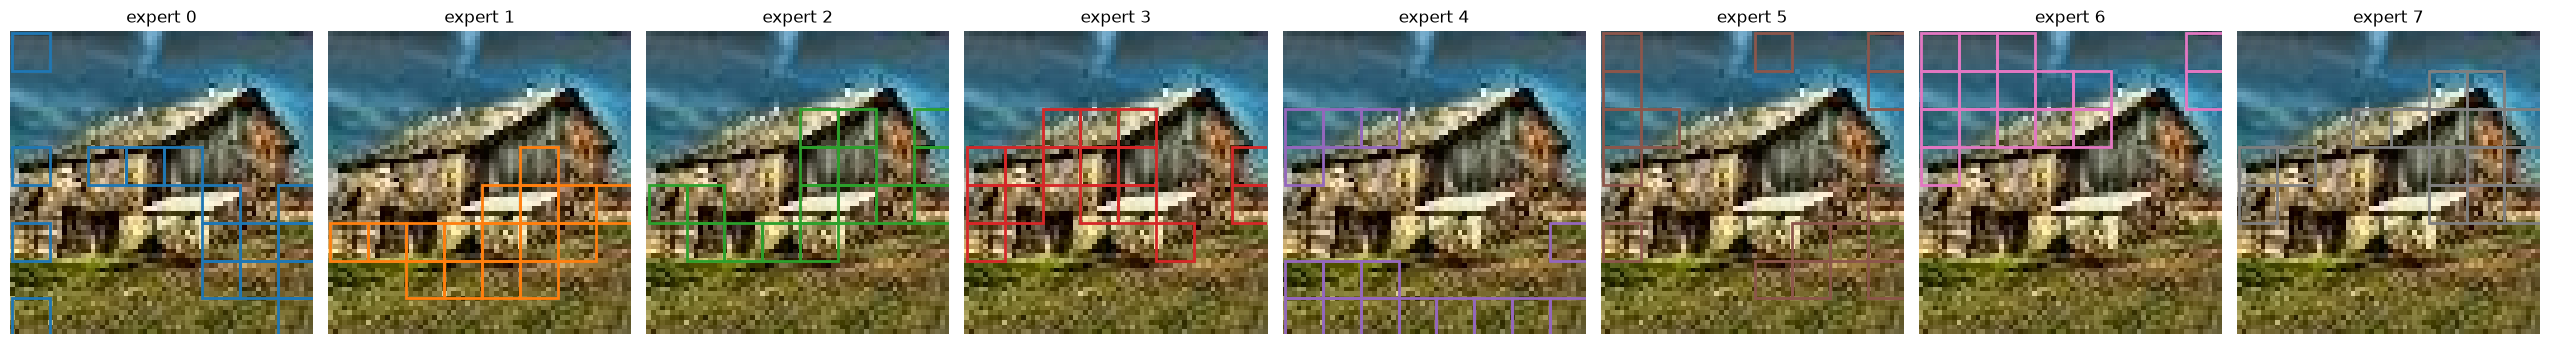

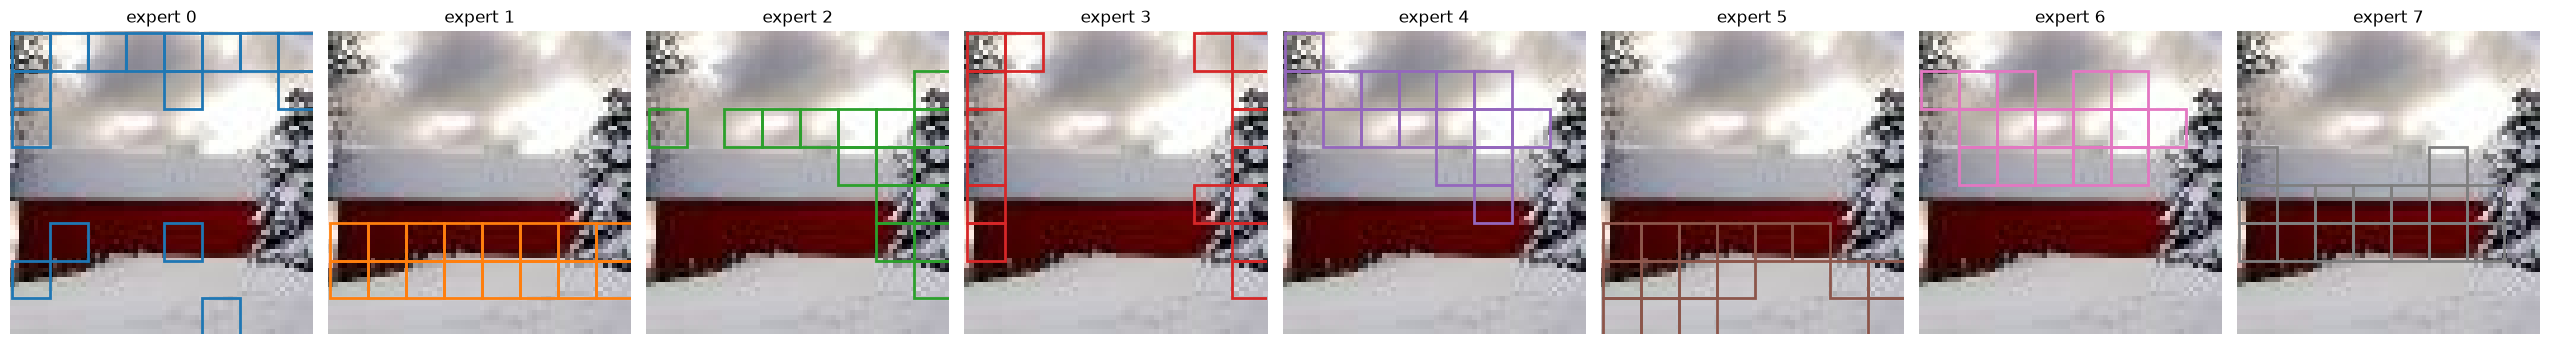

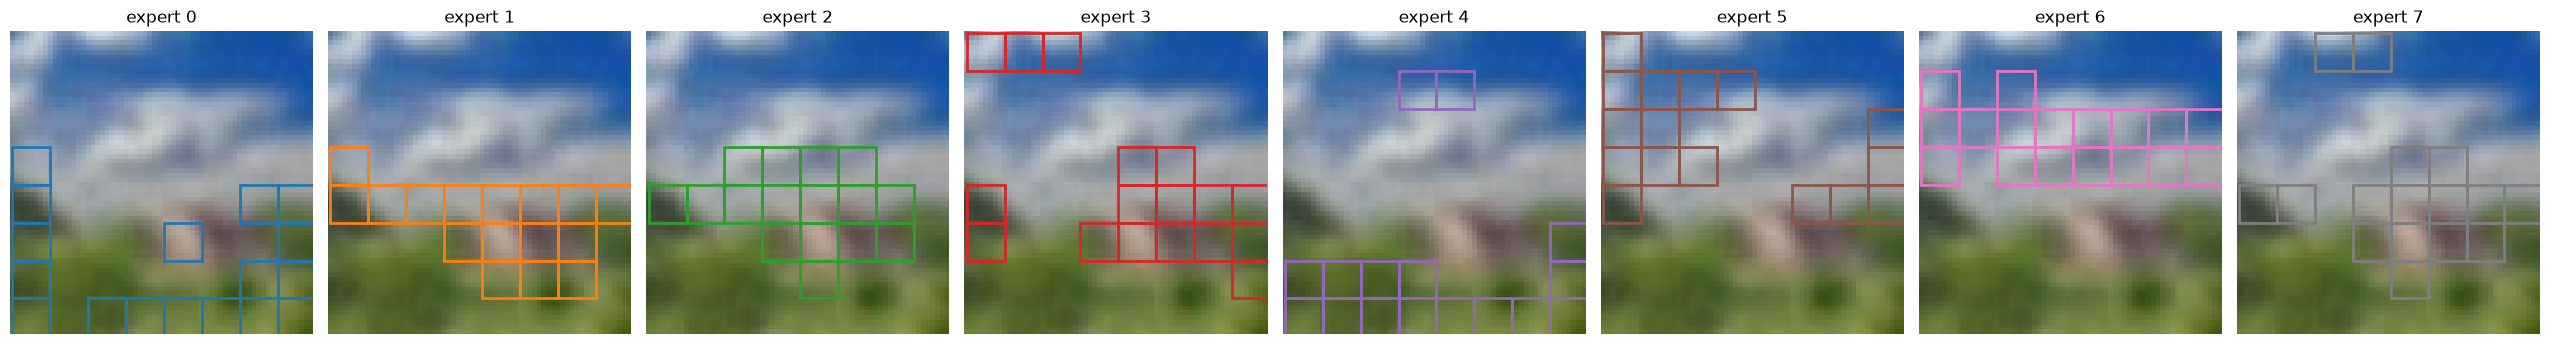

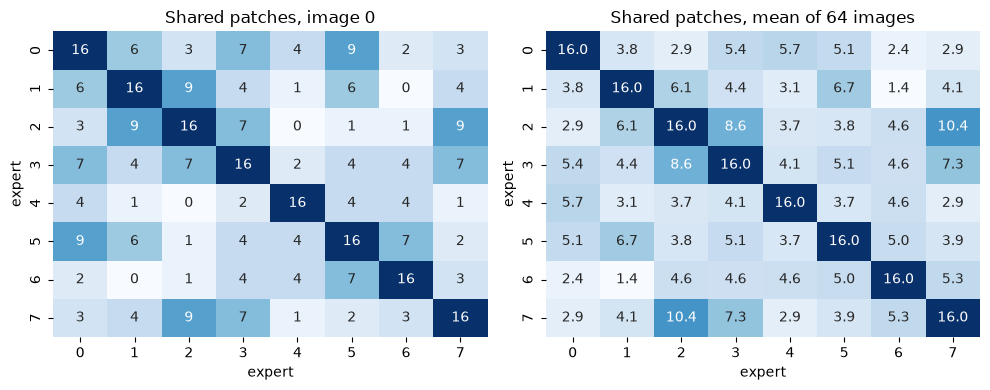

In [18]:
n = best['pmoe']
net = RUNS[n]['net']
if net is None:
    print(f'{n} was read from its log: train it again in this session to see its patches')
else:
    images, _ = next(iter(val))
    top_idx, gates, grid = expert_choices(net, images[:64])
    print(f'{n}: top_idx {top_idx.shape} = (images, experts, l patches);  patch grid {grid}')
    for i in range(3):
        plotting.show_expert_patches(images[i].numpy(), top_idx[i], grid)

    # do the experts pick different patches? (the diagonal is l; big off-diagonal numbers = no specialisation)
    k = top_idx.shape[1]
    def overlap(i):
        return np.array([[len(set(top_idx[i, a]) & set(top_idx[i, b])) for b in range(k)] for a in range(k)])
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    sns.heatmap(overlap(0), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
    ax[0].set(title='Shared patches, image 0', xlabel='expert', ylabel='expert')
    sns.heatmap(np.mean([overlap(i) for i in range(len(top_idx))], axis=0), annot=True, fmt='.1f', cmap='Blues',
                cbar=False, ax=ax[1])
    ax[1].set(title=f'Shared patches, mean of {len(top_idx)} images', xlabel='expert', ylabel='expert')
    plt.tight_layout(); plt.show()

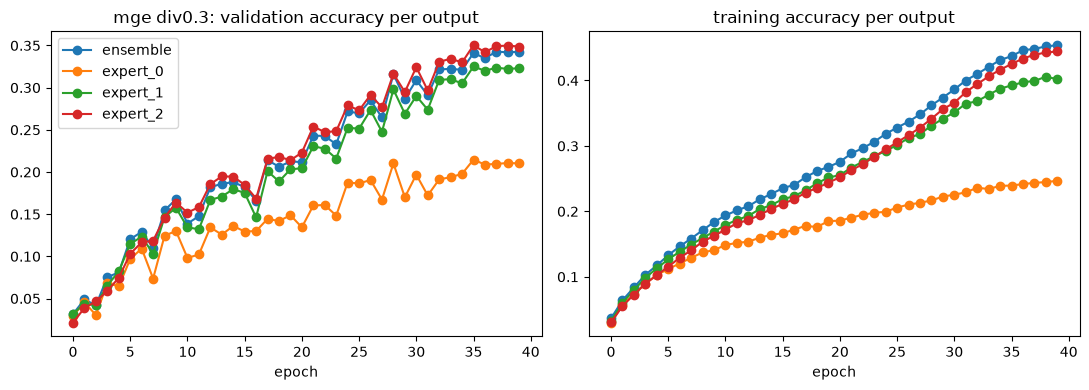

best val accuracy: {'ensemble': 0.3428, 'expert_0': 0.2147, 'expert_1': 0.3251, 'expert_2': 0.3503}


In [19]:
n = best['mge']
h = RUNS[n]['log']
outputs = ['ensemble', 'expert_0', 'expert_1', 'expert_2']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for o in outputs:
    ax[0].plot(h[f'val_{o}_accuracy'].values, marker='o', label=o)
    ax[1].plot(h[f'{o}_accuracy'].values, marker='o', label=o)
ax[0].set(title=f'{label(RUNS[n])}: validation accuracy per output', xlabel='epoch')
ax[1].set(title='training accuracy per output', xlabel='epoch')
ax[0].legend(); plt.tight_layout(); plt.show()
print('best val accuracy:', {o: round(float(h[f'val_{o}_accuracy'].max()), 4) for o in outputs})

**MGE experts.** The deepest expert (`expert_2`, on `s3`) is slightly better on its own (0.350 val acc) than the ensemble (0.343). `expert_0` (on `s1`) is weak (0.21). The gain comes from the backbone and the deep features, not from combining depths.

## Test set (once, for the two winners)
The settings were chosen on validation; the test set only reports how good the chosen models are.

In [20]:
y_test = np.concatenate([y.numpy() for _, y in test])
for m, n in best.items():
    net = RUNS[n]['net']
    if net is None:
        print(f'{m}: {n} was read from its log, no model to test (train it again in this session)')
        continue
    pred = net.predict(test, verbose=0)
    if isinstance(pred, (list, tuple)):          # MGE: the first output is the ensemble
        pred = pred[0]
    p = pred.argmax(1)
    print(f'{m:5s} {n}: test macro-F1 {f1_score(y_test, p, average="macro"):.4f}   accuracy {(p == y_test).mean():.4f}')

pmoe  pmoe_e8_l16_e2e_40ep_lr0.01_aug: test macro-F1 0.1996   accuracy 0.2690
mge   mge_div0.3_e2e_40ep_lr0.01_aug: test macro-F1 0.2578   accuracy 0.3357


## Conclusion
| model | setting | val F1 | test F1 | test acc |
|---|---|---|---|---|
| **MGE** | `div0.3` | 0.269 | **0.258** | **0.336** |
| pMoE | `e8_l16` | 0.209 | 0.200 | 0.269 |

* **MGE is the better head.** It wins on validation and on test, and the test scores sit close to validation, so choosing settings on val did not overfit.
* **The head settings barely matter.** The diversity weight changes MGE by less than 0.003 F1, and within MGE the single deepest expert matches the ensemble.
* **With augmentation, the models are now limited by training time, not by overfitting.** All runs peaked at epochs 35-39 of 40, and validation loss was still falling. The train/val accuracy gap is moderate: about 5 points for pMoE and about 10 for MGE. The next step is a longer schedule (more `EPOCHS`), not more regularisation.